# **Library**

In [1]:
import numpy as np
import pandas as pd
from importlib import reload
from modules import monte_carlo

In [2]:
reload(monte_carlo)

# **Heston Parameters**

In [3]:
V_0 = 0.028319833917909945
KAPPA = 3.4158314637296794
THETA = 0.05471611433894729
ETA = 1.949743914893052
RHO = -0.5449784854430381

heston_parameters = [KAPPA, THETA, ETA, RHO]

## **Feller Condition Check**
Define the Feller ratio as
$$2\kappa\theta / \eta^2$$

In [4]:
feller_ratio = 2*KAPPA*THETA / ETA**2
print(f'Feller ratio: {feller_ratio:.4f}')

Feller ratio: 0.0983


# **Define Constant**

In [5]:
pricing_date_1 = pd.Timestamp('2026-09-18')
valuation_date_1 = pd.Timestamp('2030-09-18')
maturity_date_1 = pd.Timestamp('2030-09-23')
PRINCIPAL_1 = 1000
S0_1 = 7650.50
CALL_LEVEL_1 = S0_1
COUPON_LEVEL_1 = 0.7 * S0_1
COUPON_RATE_1 = 0.02
THRESHOLD_LEVEL_1 = 0.7 * S0_1
r_1 = 0.0456673
N_1 = (valuation_date_1 - pricing_date_1).days
M_1 = 20000
Q_1 = 0.01151                                   # Bloomberg OVME continuous dividend yield to 2030-09-23, as of 2026-09-18
FUNDING_SPREAD_1 = 0.0                            # 0 = risk-free fair value
ISSUER_ESTIMATE_1 = 993.00                         # issuer's estimated value

# **Observation, Autocall, and Payment Date**

In [6]:
# coupon observation dates (16)
observation_date_1 = [
    pd.Timestamp('2026-12-18'), pd.Timestamp('2027-03-18'), pd.Timestamp('2027-06-21'), pd.Timestamp('2027-09-20'),
    pd.Timestamp('2027-12-20'), pd.Timestamp('2028-03-20'), pd.Timestamp('2028-06-20'), pd.Timestamp('2028-09-18'),
    pd.Timestamp('2028-12-18'), pd.Timestamp('2029-03-19'), pd.Timestamp('2029-06-18'), pd.Timestamp('2029-09-18'),
    pd.Timestamp('2029-12-18'), pd.Timestamp('2030-03-18'), pd.Timestamp('2030-06-18'), pd.Timestamp('2030-09-18'),
]

# call observation dates (12)
autocall_date_1 = [
    pd.Timestamp('2027-09-20'), pd.Timestamp('2027-12-20'), pd.Timestamp('2028-03-20'), pd.Timestamp('2028-06-20'),
    pd.Timestamp('2028-09-18'), pd.Timestamp('2028-12-18'), pd.Timestamp('2029-03-19'), pd.Timestamp('2029-06-18'),
    pd.Timestamp('2029-09-18'), pd.Timestamp('2029-12-18'), pd.Timestamp('2030-03-18'), pd.Timestamp('2030-06-18'),
]

# contingent payment dates (16), one for each observation date
payment_date_1 = [
    pd.Timestamp('2026-12-23'), pd.Timestamp('2027-03-23'), pd.Timestamp('2027-06-24'), pd.Timestamp('2027-09-23'),
    pd.Timestamp('2027-12-23'), pd.Timestamp('2028-03-23'), pd.Timestamp('2028-06-23'), pd.Timestamp('2028-09-21'),
    pd.Timestamp('2028-12-21'), pd.Timestamp('2029-03-22'), pd.Timestamp('2029-06-22'), pd.Timestamp('2029-09-21'),
    pd.Timestamp('2029-12-21'), pd.Timestamp('2030-03-21'), pd.Timestamp('2030-06-24'), pd.Timestamp('2030-09-23'),
]

## **All data converted to year fraction**

In [7]:
T_1, delta_t_1, observation_t_1, autocall_t_1, payment_t_1 = monte_carlo.year_fraction(
    N_1, pricing_date_1, valuation_date_1,
    observation_date_1, autocall_date_1, payment_date_1)

# **Product Price by Monte-Carlo**

In [8]:
product_price, product_price_vector, s_sample_path, v_sample_path = monte_carlo.monte_carlo_1(
    M_1, N_1,
    T_1, delta_t_1, observation_t_1, autocall_t_1, payment_t_1,
    S0_1, V_0, r_1, heston_parameters,
    PRINCIPAL_1, CALL_LEVEL_1, COUPON_LEVEL_1, COUPON_RATE_1, THRESHOLD_LEVEL_1,
    q=Q_1, funding_spread=FUNDING_SPREAD_1)

In [9]:
product_price

np.float64(998.5618838484896)

# **Analysis 1: Implied Issuer Funding Spread**

In [10]:
implied_spread_1 = monte_carlo.implied_funding_spread(
    ISSUER_ESTIMATE_1, s_sample_path, delta_t_1,
    observation_t_1, autocall_t_1, payment_t_1, S0_1, r_1,
    PRINCIPAL_1, CALL_LEVEL_1, COUPON_LEVEL_1, COUPON_RATE_1, THRESHOLD_LEVEL_1)

pd.Series({
    'Dividend yield q': Q_1,
    'Fair value (risk-free discounting)': product_price,
    'Issuer estimated value': ISSUER_ESTIMATE_1,
    'Implied funding spread s': implied_spread_1,
})

Dividend yield q                        0.011510
Fair value (risk-free discounting)    998.561884
Issuer estimated value                993.000000
Implied funding spread s                0.003956
dtype: float64

# **Analysis 2: Is M = 20,000 Enough?**

WLLN (Chebyshev): $P\left(|\hat{V}_M - V| \ge \epsilon\right) \le \dfrac{\sigma^2}{M\epsilon^2}$ with $\epsilon = 10$. 99% CI: $\hat{V}_M \pm 2.576\,\sigma/\sqrt{M}$.

In [11]:
EPSILON = 10
lower_1, upper_1 = monte_carlo.confidence_interval(product_price_vector, alpha=0.01)

pd.Series({
    'M': len(product_price_vector),
    'Price': np.mean(product_price_vector),
    'P(|error| >= 10) upper bound': monte_carlo.chebyshev_bound(product_price_vector, EPSILON),
    '99% CI lower': lower_1,
    '99% CI upper': upper_1,
})

M                               20000.000000
Price                             998.561884
P(|error| >= 10) upper bound        0.012751
99% CI lower                      995.653273
99% CI upper                     1001.470495
dtype: float64

## **Sampling Distribution of the MC Price**

The CLT is a statement about the **sample mean**, not the payoff. To check it directly, the whole simulation ($M = 20{,}000$ paths) is repeated $R$ times with independent seeds. If the CLT holds, the $R$ prices should be normal with standard deviation equal to the standard error $\hat\sigma/\sqrt{M}$ of a single run.

In [12]:
import matplotlib.pyplot as plt
from modules import comparison
from scipy import stats

R = 300          # independent replications (about 1 second each)

payoff_1 = dict(observation_t=list(observation_t_1), autocall_t=list(autocall_t_1), payment_t=list(payment_t_1),
                principal=PRINCIPAL_1, call_level=CALL_LEVEL_1, coupon_level=COUPON_LEVEL_1,
                coupon_rate=COUPON_RATE_1, threshold_level=THRESHOLD_LEVEL_1)

rep_prices = np.array([
    comparison.mc_cashflows(
        comparison.heston_obs_paths(M_1, N_1, delta_t_1, list(observation_t_1), S0_1, V_0, r_1 - Q_1,
                                    heston_parameters, seed=seed),
        S0_1, r_1, **payoff_1)['value'].mean()
    for seed in range(1, R + 1)])

se_1 = np.std(product_price_vector, ddof=1) / np.sqrt(M_1)     # standard error of a single run

pd.Series({
    'Replications R': R,
    'Mean of R prices': rep_prices.mean(),
    'Std dev of R prices': rep_prices.std(ddof=1),
    'Standard error of one run': se_1,
    'Skewness (normal = 0)': stats.skew(rep_prices),
    'Excess kurtosis (normal = 0)': stats.kurtosis(rep_prices),
    'Shapiro-Wilk p-value': stats.shapiro(rep_prices).pvalue,
    'Share within +/- 2.576 SE (target 99%)': (np.abs(rep_prices - rep_prices.mean()) <= 2.5758*se_1).mean(),
})

Replications R                            300.000000
Mean of R prices                          999.164822
Std dev of R prices                         1.138434
Standard error of one run                   1.129194
Skewness (normal = 0)                       0.026988
Excess kurtosis (normal = 0)               -0.034941
Shapiro-Wilk p-value                        0.969794
Share within +/- 2.576 SE (target 99%)      0.990000
dtype: float64

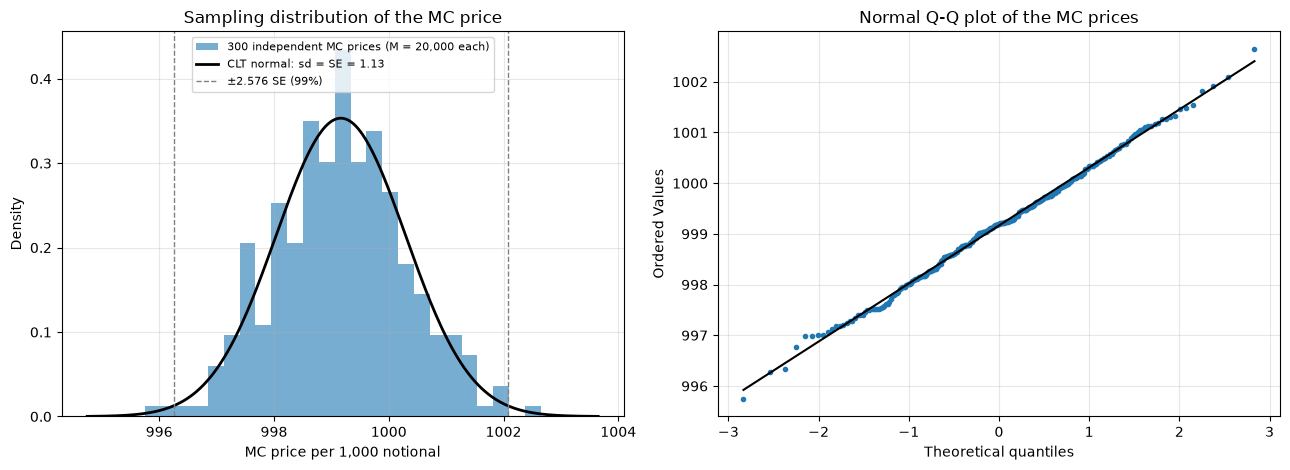

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# histogram of the R prices against the CLT normal
ax = axes[0]
ax.hist(rep_prices, bins=25, density=True, color='tab:blue', alpha=0.6,
        label=f'{R} independent MC prices (M = {M_1:,} each)')
x = np.linspace(rep_prices.min() - 1, rep_prices.max() + 1, 300)
ax.plot(x, stats.norm.pdf(x, rep_prices.mean(), se_1), color='black', lw=2, label=f'CLT normal: sd = SE = {se_1:.2f}')
ax.axvline(rep_prices.mean() - 2.5758*se_1, color='grey', ls='--', lw=1, label='±2.576 SE (99%)')
ax.axvline(rep_prices.mean() + 2.5758*se_1, color='grey', ls='--', lw=1)
ax.set_title('Sampling distribution of the MC price')
ax.set_xlabel('MC price per 1,000 notional')
ax.set_ylabel('Density')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# normal Q-Q plot: a straight line means the prices are normal
ax = axes[1]
stats.probplot(rep_prices, dist='norm', plot=ax)
ax.get_lines()[0].set(marker='o', markersize=3, color='tab:blue')
ax.get_lines()[1].set(color='black')
ax.set_title('Normal Q-Q plot of the MC prices')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# **Analysis 3: Distribution of Product Price**

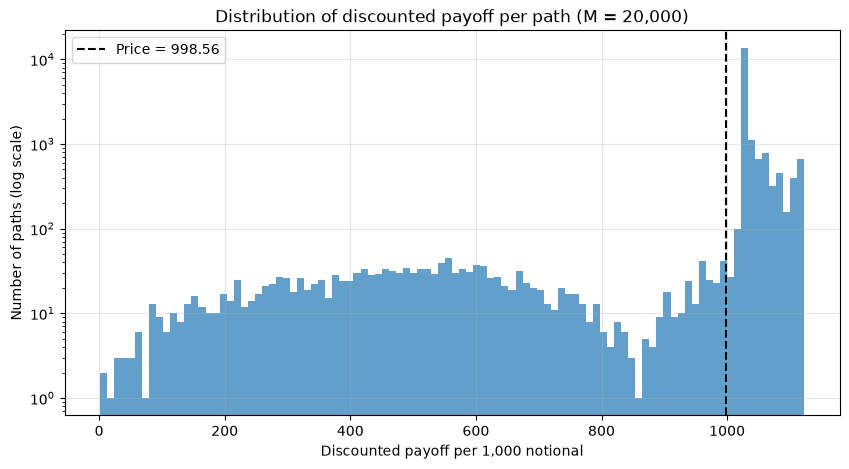

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(product_price_vector, bins=100, color='tab:blue', alpha=0.7)
plt.axvline(np.mean(product_price_vector), color='black', ls='--', label=f'Price = {np.mean(product_price_vector):,.2f}')
plt.yscale('log')
plt.title('Distribution of discounted payoff per path (M = 20,000)')
plt.xlabel('Discounted payoff per 1,000 notional')
plt.ylabel('Number of paths (log scale)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# **Analysis 4: Time-Step (N) Check**

Price Product 1 with $N = 1000, 1200, \dots, 2000$ time steps on a uniform grid ($\Delta t = T/N$, observation dates mapped to the nearest step). If the price stays flat within its 99% confidence interval and well inside $\epsilon = 10$, the daily grid $N = 1461$ is fine enough.

In [15]:
import matplotlib.pyplot as plt
from modules import comparison, discretization
reload(discretization)

M_N = 20000
N_LIST = [1000, 1200, 1400, 1600, 1800, 2000]

value_fn_1 = lambda paths: comparison.mc_cashflows(
    paths, S0_1, r_1, list(observation_t_1), list(autocall_t_1), list(payment_t_1),
    PRINCIPAL_1, CALL_LEVEL_1, COUPON_LEVEL_1, COUPON_RATE_1, THRESHOLD_LEVEL_1)['value']

price_N_1 = discretization.price_by_N(M_N, N_LIST, T_1, list(observation_t_1),
                                      S0_1, V_0, r_1 - Q_1, heston_parameters, value_fn_1)

price_N_1

,N,price,99% half-width
0,1000,997.344938,2.960764
1,1200,996.974912,2.972401
2,1400,998.641743,2.925149
3,1600,997.451654,2.968729
4,1800,997.734633,2.938680
5,2000,998.099819,2.930588


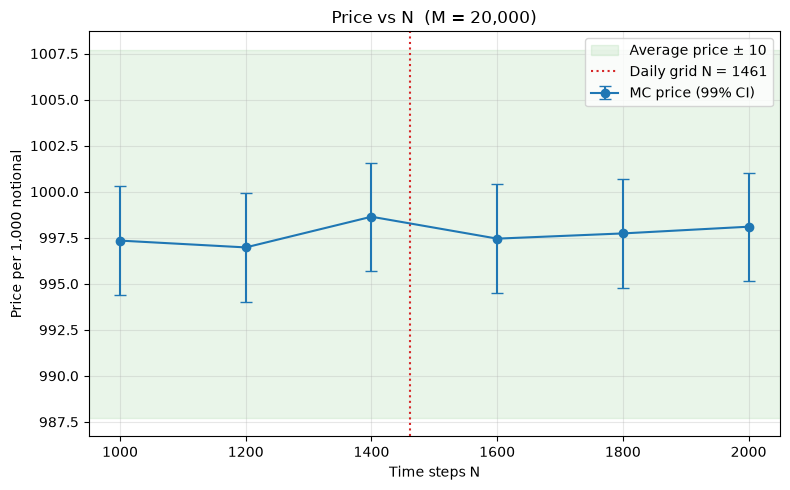

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))

mean_price = price_N_1['price'].mean()
ax.errorbar(price_N_1['N'], price_N_1['price'], yerr=price_N_1['99% half-width'],
            fmt='o-', color='tab:blue', capsize=4, label='MC price (99% CI)')
ax.axhspan(mean_price - 10, mean_price + 10, color='tab:green', alpha=0.1, label='Average price ± 10')
ax.axvline(1461, color='tab:red', ls=':', label='Daily grid N = 1461')
ax.set_xlabel('Time steps N')
ax.set_ylabel('Price per 1,000 notional')
ax.set_title(f'Price vs N  (M = {M_N:,})')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# **Flat-Volatility Binomial (CRR)**

In [17]:
import matplotlib.pyplot as plt
from modules import binomial
reload(binomial)

surface = pd.read_excel('Data/ATM_IV.xlsx', sheet_name='OVDV')

MONEYNESS = [0.70, 0.80, 0.90, 0.95, 1.00]

## **Volatility Choice**

In [18]:
# flat vols from the surface at the product maturity: 70% (barrier) to 100% (autocall) moneyness
vols_1 = [binomial.surface_vol(surface, T_1, m) for m in MONEYNESS]
pd.DataFrame({'moneyness': MONEYNESS, 'vol': vols_1})

,moneyness,vol
0,0.70,0.253952
1,0.80,0.238868
2,0.90,0.223791
3,0.95,0.216341
4,1.00,0.208892


## **ATM vol and 0.7 vol result**

In [19]:
bin_args_1 = dict(
    T=T_1, observation_t=list(observation_t_1), autocall_t=list(autocall_t_1), payment_t=list(payment_t_1),
    s_0=S0_1, r=r_1, q=Q_1,
    principal=PRINCIPAL_1, call_level=CALL_LEVEL_1, coupon_level=COUPON_LEVEL_1,
    coupon_rate=COUPON_RATE_1, threshold_level=THRESHOLD_LEVEL_1)

# convergence at the ATM vol and at the 70% moneyness vol: N, 2N, ..., 10N steps
df_conv_1 = binomial.crr_convergence(N_1, 10, sigma=vols_1[-1], **bin_args_1)       # ATM (100%)
df_conv_1_70 = binomial.crr_convergence(N_1, 10, sigma=vols_1[0], **bin_args_1)     # 70% moneyness

pd.DataFrame({'num_steps': df_conv_1['num_steps'],
              f'ATM vol ({vols_1[-1]:.2%})': df_conv_1['Value'],
              f'70% vol ({vols_1[0]:.2%})': df_conv_1_70['Value']})

,num_steps,ATM vol (20.89%),70% vol (25.40%)
0,1461,995.385273,964.664275
1,2922,997.396618,963.995516
2,4383,995.965725,966.330650
3,5844,996.148110,965.108426
4,7305,995.598904,966.640695
5,8766,995.637187,965.305981
6,10227,996.186815,965.674793
7,11688,996.864662,965.318006
8,13149,996.248806,966.191821
9,14610,996.121442,966.286636


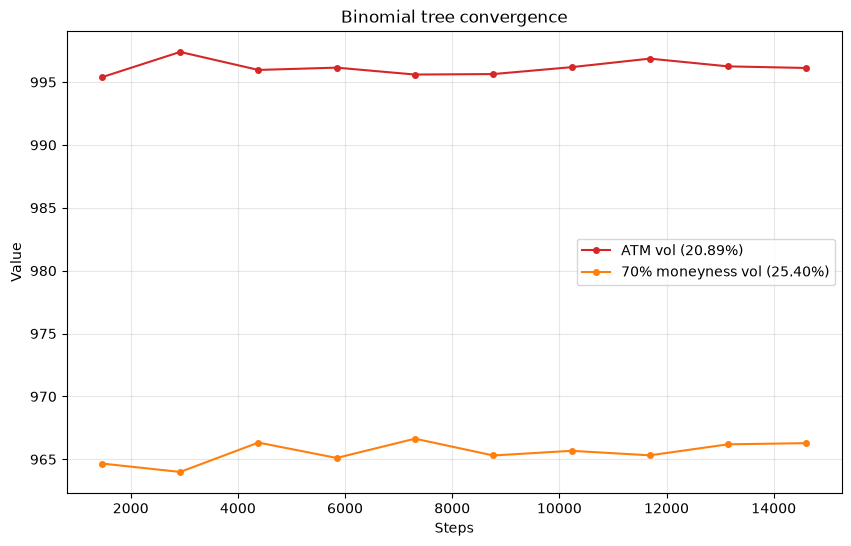

In [20]:
fig, ax1 = plt.subplots(figsize=(10,6))
ax1.plot(df_conv_1['num_steps'], df_conv_1['Value'], '-o', markersize=4, color='tab:red',
         label=f'ATM vol ({vols_1[-1]:.2%})')
ax1.plot(df_conv_1_70['num_steps'], df_conv_1_70['Value'], '-o', markersize=4, color='tab:orange',
         label=f'70% moneyness vol ({vols_1[0]:.2%})')
ax1.set_xlabel('Steps')
ax1.set_ylabel('Value')
ax1.set_title('Binomial tree convergence')
ax1.legend()
ax1.grid(True, alpha=0.3)
plt.show()

In [21]:
# vol sensitivity at 10N steps
df_vols_1 = binomial.crr_vols(10*N_1, vols_1, **bin_args_1)
df_vols_1.insert(0, 'moneyness', MONEYNESS)
df_vols_1

,moneyness,vol,Value
0,0.70,0.253952,966.286636
1,0.80,0.238868,976.834667
2,0.90,0.223791,986.815551
3,0.95,0.216341,990.878144
4,1.00,0.208892,996.121442


# **Flat-Volatility Monte Carlo**

In [22]:
# flat-vol Monte Carlo: same simulator and seed as the Heston MC, with eta = 0 and v_0 = theta = sigma^2,
# so the variance stays at sigma^2 and the index follows geometric Brownian motion
def flat_monte_carlo_1(sigma:float):
    price, vector, _, _ = monte_carlo.monte_carlo_1(
        M_1, N_1,
        T_1, delta_t_1, observation_t_1, autocall_t_1, payment_t_1,
        S0_1, sigma**2, r_1, [KAPPA, sigma**2, 0.0, RHO],
        PRINCIPAL_1, CALL_LEVEL_1, COUPON_LEVEL_1, COUPON_RATE_1, THRESHOLD_LEVEL_1,
        q=Q_1, funding_spread=FUNDING_SPREAD_1)
    return price, np.asarray(vector)

M_LIST = [2000, 4000, 6000, 8000, 10000, 12000, 14000, 16000, 18000, 20000]

## **Volatility Choice**

In [23]:
# same flat vols as the binomial section: 70% (barrier) to 100% (autocall) moneyness
pd.DataFrame({'moneyness': MONEYNESS, 'vol': vols_1})

,moneyness,vol
0,0.70,0.253952
1,0.80,0.238868
2,0.90,0.223791
3,0.95,0.216341
4,1.00,0.208892


## **ATM vol and 0.7 vol result**

In [24]:
# full runs at the ATM vol and at the 70% moneyness vol (path values kept for the convergence check)
flat_runs_1 = {m: flat_monte_carlo_1(v) for m, v in [(1.00, vols_1[-1]), (0.70, vols_1[0])]}

# convergence: price using the first M paths, M = 2000, 4000, ..., 20000
df_flat_conv_1 = pd.DataFrame({'num_paths': M_LIST,
                               f'ATM vol ({vols_1[-1]:.2%})': [flat_runs_1[1.00][1][:m].mean() for m in M_LIST],
                               f'70% vol ({vols_1[0]:.2%})': [flat_runs_1[0.70][1][:m].mean() for m in M_LIST]})
df_flat_conv_1

,num_paths,ATM vol (20.89%),70% vol (25.40%)
0,2000,1001.115349,975.235641
1,4000,998.164598,970.027853
2,6000,997.795556,968.549562
3,8000,998.142707,967.998917
4,10000,997.543955,967.037899
5,12000,997.228635,967.066552
6,14000,997.166915,967.278752
7,16000,997.484117,967.690481
8,18000,997.360433,967.803572
9,20000,996.669964,967.046621


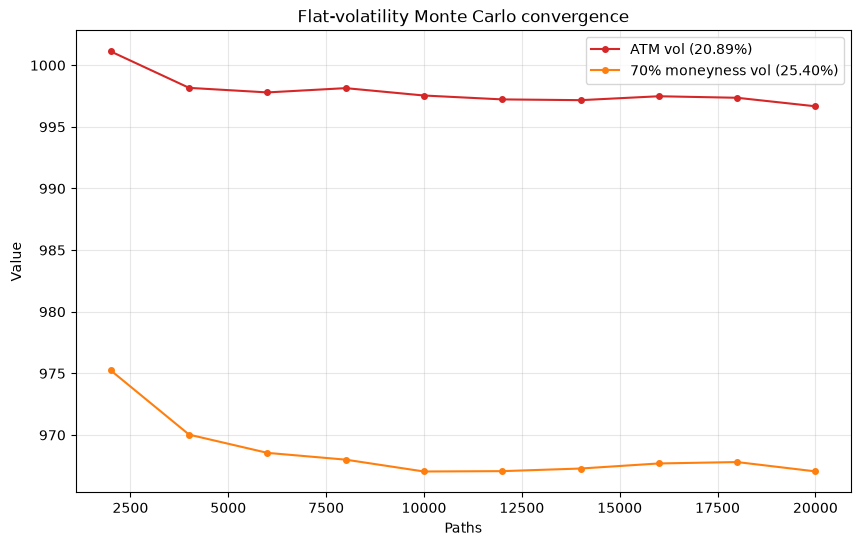

In [25]:
fig, ax1 = plt.subplots(figsize=(10,6))
ax1.plot(df_flat_conv_1['num_paths'], df_flat_conv_1.iloc[:, 1], '-o', markersize=4, color='tab:red',
         label=f'ATM vol ({vols_1[-1]:.2%})')
ax1.plot(df_flat_conv_1['num_paths'], df_flat_conv_1.iloc[:, 2], '-o', markersize=4, color='tab:orange',
         label=f'70% moneyness vol ({vols_1[0]:.2%})')
ax1.set_xlabel('Paths')
ax1.set_ylabel('Value')
ax1.set_title('Flat-volatility Monte Carlo convergence')
ax1.legend()
ax1.grid(True, alpha=0.3)
plt.show()

In [26]:
# vol sensitivity at M = 20,000 paths (reuses the ATM and 70% runs above)
for m, v in zip(MONEYNESS, vols_1):
    if m not in flat_runs_1:
        flat_runs_1[m] = flat_monte_carlo_1(v)

df_flat_vols_1 = pd.DataFrame({'moneyness': MONEYNESS, 'vol': vols_1,
                               'Value': [flat_runs_1[m][0] for m in MONEYNESS]})
df_flat_vols_1

,moneyness,vol,Value
0,0.70,0.253952,967.046621
1,0.80,0.238868,976.854904
2,0.90,0.223791,986.874664
3,0.95,0.216341,991.632312
4,1.00,0.208892,996.669964


## **Heston vs Flat Volatility**

In [27]:
heston_vector = np.asarray(product_price_vector)
lower, upper = monte_carlo.confidence_interval(heston_vector)
rows = [{'Model': 'Heston MC', 'Vol': np.nan, 'MC price': product_price,
         '99% CI lower': lower, '99% CI upper': upper}]

for label, m in [('ATM', 1.00), ('70% moneyness', 0.70)]:

    price, vector = flat_runs_1[m]
    sigma = vols_1[MONEYNESS.index(m)]
    lower, upper = monte_carlo.confidence_interval(vector)

    # model effect on the same paths: Heston minus flat, path by path
    diff_lower, diff_upper = monte_carlo.confidence_interval(heston_vector - vector)

    tree = df_vols_1.loc[np.isclose(df_vols_1['moneyness'], m), 'Value'].iloc[0]

    rows.append({'Model': f'Flat MC, {label} vol', 'Vol': sigma, 'MC price': price,
                 '99% CI lower': lower, '99% CI upper': upper,
                 'Binomial tree (same vol)': tree,
                 'Heston - flat MC': product_price - price,
                 'Heston - flat 99% CI lower': diff_lower, 'Heston - flat 99% CI upper': diff_upper})

flat_summary_1 = pd.DataFrame(rows).set_index('Model')
flat_summary_1

,Vol,MC price,99% CI lower,99% CI upper,Binomial tree (same vol),Heston - flat MC,Heston - flat 99% CI lower,Heston - flat 99% CI upper
Model,,,,,,,,
Heston MC,NaN,998.561884,995.653273,1001.470495,NaN,NaN,NaN,NaN
"Flat MC, ATM vol",0.208892,996.669964,994.040907,999.299021,996.121442,1.891920,-1.379378,5.163217
"Flat MC, 70% moneyness vol",0.253952,967.046621,963.692622,970.400621,966.286636,31.515262,27.829700,35.200825
